<a href="https://colab.research.google.com/github/adalves-ufabc/2026.Q3-PLN/blob/main/2026_Q3_PLN_AULA_17_Notebook_38.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processamento de Linguagem Natural [2026-Q3]**
Prof. Alexandre Donizeti Alves

## **Sistema de Perguntas e Respostas (*Question/Answering*)** **[LangChain]**
---



Um **Sistema de Perguntas e Respostas** (*Question/Answering*, *Q&A*) é uma técnica de PLN projetada para responder a perguntas formuladas em linguagem natural. Esses sistemas são frequentemente utilizados para fornecer respostas a perguntas baseadas em texto ou em documentos, e podem funcionar em diferentes contextos e com diferentes tipos de dados.

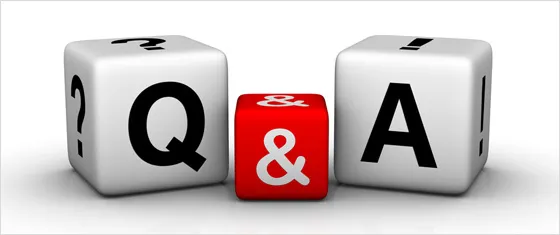

Alguns aspectos:

1. **Entrada**: o sistema recebe uma pergunta formulada em linguagem natural, por exemplo, "Qual é a capital da França?".

2. **Processamento**: o sistema analisa a pergunta e busca informações relevantes em um conjunto de dados, que pode ser um banco de dados, um córpus de textos, ou um documento específico. Isso pode envolver técnicas como análise de texto, recuperação de informações e compreensão de linguagem.

3. **Resposta**: o sistema gera uma resposta com base nas informações encontradas. Em alguns casos, a resposta pode ser diretamente extraída do texto, enquanto em outros, pode ser inferida a partir de várias fontes de dados.

4. **Tipo de Dados**: sistemas de Q&A podem trabalhar com diferentes tipos de dados, incluindo texto não estruturado (como documentos ou artigos), dados estruturados (como tabelas ou bancos de dados) e dados multimodais (como imagens e textos).

5. **Modelos e Técnicas**: esses sistemas podem usar modelos de linguagem avançados ou técnicas tradicionais de recuperação de informações e análise semântica.

6. **Aplicações**: são usados em uma variedade de contextos, incluindo assistentes virtuais, suporte ao cliente, sistemas de ajuda online e análise de grandes volumes de texto.

#### **LangChain**

In [ ]:
#@title Instalando o pacote LangChain
!pip install langchain

In [ ]:
#@title Versão do LangChain

import langchain

print(langchain.__version__)

1.4.8


In [ ]:
#@title Integração com o pacote da OpenAI

!pip install langchain-openai

In [ ]:
#@title Definindo a chave da API da OpenAI
from getpass import getpass

OPENAI_API_KEY = getpass()

··········


### **RAG**

RAG (*Retrieval-Augmented Generation*), ou Geração Aumentada por Recuperação, é uma técnica que combina dois processos: a recuperação de informações em uma base de conhecimento e a geração de respostas por um Grande Modelo de Linguagem (LLM).

A ideia é simples: em vez de pedir que o LLM responda apenas com base no conhecimento adquirido durante seu treinamento, fornecemos informações relevantes de documentos externos para que ele utilize essas informações na elaboração da resposta.

**Como funciona o RAG?**

O funcionamento pode ser dividido em duas etapas principais:

- *Retrieval* (Recuperação): busca informações relevantes em uma base de documentos, de acordo com a pergunta do usuário.
- *Generation* (Geração): utiliza as informações recuperadas como contexto para que o LLM produza uma resposta.

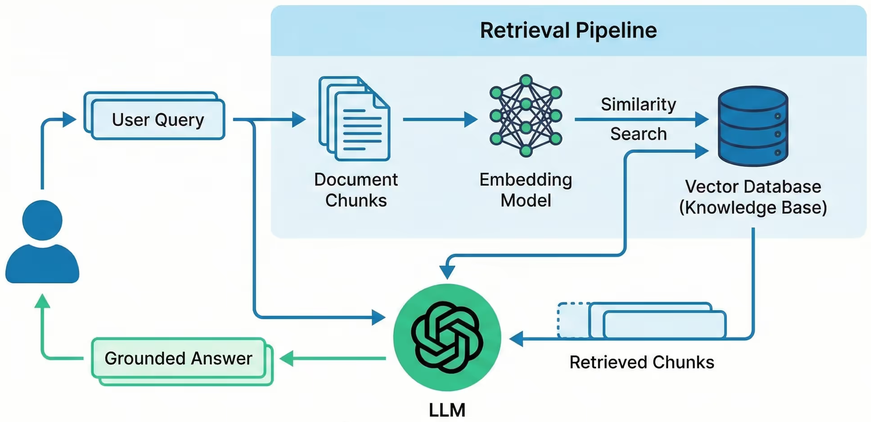

O fluxo geral é:

1. O usuário faz uma pergunta.
2. O sistema procura trechos relevantes nos documentos.
3. Os trechos recuperados são organizados em um contexto.
4. O contexto e a pergunta são enviados ao LLM.
5. O modelo produz uma resposta fundamentada no conteúdo recuperado.

**Quais são as vantagens do RAG?**

- Permite utilizar documentos específicos como fonte de conhecimento.
- Facilita a atualização das informações sem precisar retreinar o LLM.
- Pode reduzir respostas incorretas ao fornecer contexto relevante.
- Permite construir sistemas de perguntas e respostas sobre documentos.
- Possibilita apresentar fontes que ajudam a verificar as respostas.
>

É importante destacar que RAG não elimina completamente as alucinações. A qualidade da resposta depende da qualidade dos documentos, da recuperação dos trechos e da capacidade do LLM de interpretar o contexto.

### **PDF**

Arquivos PDF frequentemente contêm dados não estruturados que não estão disponíveis em outras fontes. Eles podem ser bastante longos e, ao contrário dos arquivos de texto simples, geralmente não podem ser inseridos diretamente no *prompt* de um modelo de linguagem.

>
Neste exemplo, você criará um sistema que pode responder a perguntas sobre arquivos PDF. O foco será o QA baseado em documentos, utilizando RAG.

#### Obtenção do PDF sem upload

O relatório público é baixado diretamente para o ambiente de execução.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

PDF_URL = (
    "https://s1.q4cdn.com/806093406/files/doc_downloads/2023/"
    "414759-1-_5_Nike-NPS-Combo_Form-10-K_WR.pdf"
)
PDF_PATH = Path("relatorio_nike_2023.pdf")

if not PDF_PATH.exists():
    urlretrieve(PDF_URL, PDF_PATH)

print(f"PDF disponível em: {PDF_PATH.resolve()}")
print(f"Tamanho: {PDF_PATH.stat().st_size / (1024 * 1024):.2f} MB")

PDF disponível em: /content/relatorio_nike_2023.pdf
Tamanho: 3.30 MB


#### Extração direta com `pypdf`

`PdfReader` acessa cada página e extrai seu texto. Cada página é convertida em um `Document` do `langchain-core`, preservando a página nos metadados. A numeração começa em 1.

In [ ]:
!pip install pypdf

In [ ]:
from pypdf import PdfReader
from langchain_core.documents import Document

reader = PdfReader(str(PDF_PATH))
docs = []

for page_number, page in enumerate(reader.pages, start=1):
    page_text = page.extract_text() or ""
    if page_text.strip():
        docs.append(
            Document(
                page_content=page_text,
                metadata={"source": PDF_PATH.name, "page": page_number},
            )
        )

print(f"Total de páginas: {len(reader.pages)}")
print(f"Páginas com texto: {len(docs)}")

Total de páginas: 106
Páginas com texto: 106


In [ ]:
# inspecione o início de uma página e seus metadados
print(docs[0].page_content[:1200])
print("\\nMetadados:", docs[0].metadata)

FORM 10-KFORM 10-K
\nMetadados: {'source': 'relatorio_nike_2023.pdf', 'page': 1}


**Observação:** `pypdf` extrai texto de PDFs digitais. Se as páginas forem imagens digitalizadas, será necessário OCR. Tabelas complexas e colunas também podem exigir tratamento adicional.

#### Divisão do texto em trechos (*chunks*)

Trechos menores facilitam a recuperação e cabem melhor na janela de contexto. A sobreposição reduz a perda de contexto nas fronteiras.

In [ ]:
!pip install langchain-text-splitters

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=180,
    add_start_index=True,
)

splits = text_splitter.split_documents(docs)

print(f"Páginas: {len(docs)} | Trechos: {len(splits)}")
print(splits[0].page_content[:1000])
print("Metadados:", splits[0].metadata)

Páginas: 106 | Trechos: 498
FORM 10-KFORM 10-K
Metadados: {'source': 'relatorio_nike_2023.pdf', 'page': 1, 'start_index': 0}


#### *Embeddings* e banco vetorial Chroma

*Embeddings* representam semanticamente os trechos em vetores. O Chroma armazena esses vetores e permite recuperar trechos relacionados à pergunta.

In [ ]:
!pip install langchain-chroma

In [ ]:
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma

embeddings = OpenAIEmbeddings( model="text-embedding-3-small", api_key=OPENAI_API_KEY )
vectorstore = Chroma.from_documents(
    documents = splits,
    embedding = embeddings,
    collection_name = "rag_nike_aula",
)
print("Índice vetorial criado.")

Índice vetorial criado.


#### Configuração do modelo de linguagem

O modelo solicitado é `gpt-6-luna`, acessado por `ChatOpenAI`. A disponibilidade desse identificador depende de ele estar habilitado para sua conta e *endpoint*.

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI( model="gpt-6-luna", api_key=OPENAI_API_KEY )

#### Recuperação de documentos

O parâmetro `k` define quantos trechos serão retornados. Um `k` baixo pode omitir evidências; um `k` alto pode trazer contexto redundante.

In [ ]:
def recuperar_documentos(pergunta: str, k: int = 4):
    return vectorstore.similarity_search(pergunta, k=k)

pergunta_teste = "Quais são os principais riscos descritos pela NIKE?"
documentos_recuperados = recuperar_documentos(pergunta_teste, k=4)

print(f"Trechos recuperados: {len(documentos_recuperados)}")
for i, doc in enumerate(documentos_recuperados, start=1):
    print(f"\\n--- Trecho {i} | página {doc.metadata.get('page')} ---")
    print(doc.page_content[:700])

Trechos recuperados: 4
\n--- Trecho 1 | página 13 ---
introduction; the ability to secure and protect trademarks, patents and other intellectual property; product performance and 
quality; customer service; adverse publicity and an inability to maintain NIKE's reputation and brand image, including without 
limitation, through social media or in connection with brand damaging events; the loss of significant customers or suppliers; 
dependence on distributors and licensees; business disruptions; increased costs of freight and transportation to meet delivery 
deadlines; increases in borrowing costs due to any decline in NIKE's debt ratings; changes in business strategy or development 
plans; general risks associated with doing business outside of 
\n--- Trecho 2 | página 13 ---
Thus, to the extent that reports issued by securities analysts contain any projections, forecasts or opinions, such reports are not 
the responsibility of NIKE.
Risk Factors
The risks included here are not exhausti

#### Construção manual da cadeia RAG

A recuperação e a composição do prompt são explícitas, com `ChatPromptTemplate` e `StrOutputParser`.

O modelo deve responder somente com base no contexto e indicar as páginas utilizadas.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """Você é um assistente que responde perguntas com base em documentos.
Use somente as informações do CONTEXTO.
Se o contexto não contiver a resposta, diga que não encontrou informação suficiente.
Responda em português, de forma objetiva.
Ao final, indique as páginas consultadas usando [p. N].

CONTEXTO:
{context}"""
    ),
    ("human", "Pergunta: {question}"),
])

rag_cadeia = prompt | modelo | StrOutputParser()

def responder(pergunta: str, k: int = 4):
    fontes = recuperar_documentos(pergunta, k=k)
    contexto = "\\n\\n".join(
        f"[p. {doc.metadata.get('page', '?')}] {doc.page_content}"
        for doc in fontes
    )
    resposta = rag_cadeia.invoke({
        "context": contexto,
        "question": pergunta,
    })
    return {"question": pergunta, "answer": resposta, "context": fontes}

#### Primeira pergunta e apresentação da resposta

Além do texto gerado, exibimos os trechos recuperados para avaliar se a resposta está apoiada em evidências.

In [ ]:
from IPython.display import display, Markdown

resultado = responder(
    "Quem se juntou à NIKE em 1998?",
    k=4
)

# Apresenta a resposta em Markdown
display(Markdown(
    "### Resposta\n\n" + resultado["answer"]
))

# Organiza as fontes recuperadas
print("\n### Fontes recuperadas")

for i, doc in enumerate(resultado["context"], start=1):

    pagina = doc.metadata.get("page", "Não identificada")

    print(
        f"{i}. Página {pagina} | "
        f"{len(doc.page_content)} caracteres"
    )

### Resposta

Heidi O’Neill e Monique S. Matheson se juntaram à NIKE em 1998. [p. 12]


### Fontes recuperadas
1. Página 12 | 995 caracteres
2. Página 106 | 67 caracteres
3. Página 12 | 920 caracteres
4. Página 5 | 996 caracteres


#### Exemplos de perguntas diferentes

As perguntas exploram aspectos distintos do relatório.

In [ ]:
perguntas = [
    "Qual foi a receita da NIKE no exercício fiscal de 2023?",
    "Quais fatores podem afetar os resultados financeiros da empresa?",
    "Quais são as principais estratégias de negócio mencionadas no relatório?",
    "Quais informações o documento apresenta sobre concorrência?",
]

resultados_perguntas = []

for pergunta in perguntas:

    item = responder(pergunta, k=4)
    resultados_perguntas.append(item)

    # Apresenta a pergunta e a resposta
    display(Markdown(
        f"### Pergunta\n\n{pergunta}\n\n"
        f"### Resposta\n\n{item['answer']}"
    ))

    # Organiza as fontes recuperadas
    fontes = "\n".join(
        f"- Página {d.metadata.get('page', 'Não identificada')} "
        f"({len(d.page_content)} caracteres)"
        for d in item["context"]
    )

    display(Markdown(
        f"**Páginas recuperadas:**\n\n{fontes}"
    ))

    print("-" * 80)

### Pergunta

Qual foi a receita da NIKE no exercício fiscal de 2023?

### Resposta

A receita da NIKE no exercício fiscal de 2023 foi de US$ 51,2 bilhões. [p. 32, p. 37]

**Páginas recuperadas:**

- Página 39 (319 caracteres)
- Página 49 (911 caracteres)
- Página 32 (993 caracteres)
- Página 37 (942 caracteres)

--------------------------------------------------------------------------------


### Pergunta

Quais fatores podem afetar os resultados financeiros da empresa?

### Resposta

Os resultados financeiros da empresa podem ser afetados por:

- **Condições econômicas adversas**, como inflação e juros elevados ou recessão, que podem reduzir os gastos dos consumidores e a demanda, aumentar estoques e cancelamentos, e pressionar receitas e margens. [pp. 14–15]
- **Dificuldades financeiras dos varejistas**, que podem reduzir pedidos ou adiar investimentos em merchandising e no ambiente de venda. [p. 15]
- **Mudanças climáticas e questões de sustentabilidade**, bem como respostas legais, regulatórias ou de mercado a esses temas. [p. 15]
- **Processos judiciais, reclamações e investigações governamentais**, que podem resultar em perdas, multas ou penalidades. [p. 92]
- **Restrições e exigências regulatórias**, incluindo regras sobre transferência de moeda, clima e segurança de produtos; violações de leis anticorrupção também podem gerar sanções e prejudicar os resultados. [p. 24]

**Páginas recuperadas:**

- Página 14 (879 caracteres)
- Página 15 (989 caracteres)
- Página 92 (947 caracteres)
- Página 24 (923 caracteres)

--------------------------------------------------------------------------------


... (2 outputs left out)

--------------------------------------------------------------------------------


### Pergunta

Quais informações o documento apresenta sobre concorrência?

### Resposta

O documento afirma que o setor de calçados, vestuário e equipamentos esportivos é altamente competitivo em todo o mundo. A empresa concorre com fabricantes de calçados e roupas esportivas e de lazer, empresas de equipamentos esportivos e companhias com linhas diversificadas desses produtos. Também disputa mercado com varejistas multimarcas e plataformas de comércio digital.

A concorrência inclui produtos, tecnologia, gastos com marketing e patrocínios, preços, custos de produção, atendimento ao cliente, plataformas e serviços digitais, experiências oferecidas aos consumidores e presença nas redes sociais. [p. 9] [p. 14]

**Páginas recuperadas:**

- Página 9 (951 caracteres)
- Página 95 (185 caracteres)
- Página 14 (898 caracteres)
- Página 31 (39 caracteres)

--------------------------------------------------------------------------------


### **Página Web**

Vamos utilizar uma página da NASA que apresenta informações sobre a missão Perseverance em Marte.

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://science.nasa.gov/mission/mars-sample-return/perseverance-rover/"

# Acessa a página
resposta = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)

resposta.raise_for_status()

# Interpreta o HTML
sopa = BeautifulSoup(resposta.text, "html.parser")

# Remove elementos desnecessários
for elemento in sopa(["script", "style", "nav", "footer", "header"]):
    elemento.decompose()

# Extrai o título
titulo = sopa.title.get_text(strip=True) if sopa.title else "Página da NASA"

# Extrai o conteúdo textual
texto = sopa.get_text(separator="\n", strip=True)

print("Título:", titulo)
print("Quantidade de caracteres:", len(texto))

print("\nInício do conteúdo:")
print(texto[:100])

Título: Mars Perseverance Rover - NASA Science
Quantidade de caracteres: 7927

Início do conteúdo:
Mars Perseverance Rover - NASA Science
Search
Suggested Searches
Artemis
ISS
Roman
Webb
Quesst
Moon 


**Criando o documento**

O LangChain utiliza a classe `Document` para armazenar o conteúdo e os metadados dos documentos.

In [ ]:
from langchain_core.documents import Document

documento = Document(
    page_content=texto,
    metadata={
        "titulo": titulo,
        "fonte": url
    }
)

print("Documento criado!")
print("Título:", documento.metadata["titulo"])
print("Caracteres:", len(documento.page_content))

Documento criado!
Título: Mars Perseverance Rover - NASA Science
Caracteres: 7927


**Dividindo o documento em *chunks***

Vamos dividir o conteúdo em trechos menores, com sobreposição entre eles.

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

divisor = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150
)

documentos = divisor.split_documents([documento])

print("Quantidade de chunks:", len(documentos))

Quantidade de chunks: 9


Visualizando os primeiros trechos:

In [ ]:
for i, doc in enumerate(documentos[:3], start=1):

    print(f"\nCHUNK {i}")
    print("-" * 60)
    print(doc.page_content[:50])


CHUNK 1
------------------------------------------------------------
Mars Perseverance Rover - NASA Science
Search
Sugg

CHUNK 2
------------------------------------------------------------
Astronauts
Commercial Space
Destinations
Spaceship

CHUNK 3
------------------------------------------------------------
Drones & You
Technology
Technology Transfer & Spin


**Criando os *embeddings***

Os *embeddings* transformam os textos em representações vetoriais, permitindo realizar buscas por similaridade semântica.

In [ ]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    api_key=OPENAI_API_KEY
)

print("Modelo de embeddings configurado!")

Modelo de embeddings configurado!


**Criando o banco vetorial Chroma**

Os *chunks* e seus *embeddings* serão armazenados no banco vetorial.

In [ ]:
from langchain_chroma import Chroma

banco_vetorial = Chroma.from_documents(
    documents = documentos,
    embedding = embeddings,
    collection_name="nasa_perseverance"
)

print("Banco vetorial criado com sucesso!")

Banco vetorial criado com sucesso!


**Criando o `Retriever`**

O `Retriever` recupera os trechos mais relevantes de acordo com a pergunta.

In [ ]:
recuperador = banco_vetorial.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 4}
)

print("Retriever configurado!")

Retriever configurado!


**Testando a recuperação de informações**

Antes de utilizar o LLM, vamos verificar quais documentos são recuperados.

In [ ]:
pergunta = "Por que a NASA está explorando a cratera Jezero?"

documentos_recuperados = recuperador.invoke(pergunta)

for i, doc in enumerate(documentos_recuperados, start=1):

    print(f"\nDOCUMENTO RECUPERADO {i}")
    print("-" * 60)
    print(doc.page_content)


DOCUMENTO RECUPERADO 1
------------------------------------------------------------
1 min read
TIME Best Inventions of 2026
article
1 month ago
Highlights
11 min read
La NASA anuncia la cobertura de la misión lunar Artemis II
article
8 months ago
15 min read
Agenda diaria de la misión a la Luna de Artemis II de la NASA
article
8 months ago
6 min read
La NASA refuerza Artemis: añade una misión y perfecciona su arquitectura general
article
9 months ago
Mars Sample Return
Mars Sample Return
Mars Perseverance Rover
The Mars Perseverance rover is the first leg the Mars Sample Return Campaign’s interplanetary relay team. Its job is to collect and cache samples on Mars.
Searching for Ancient Life
Mars Rock Samples
The
Mars Perseverance rover
is the first leg of NASA and ESA (European Space Agency)
Mars Sample Return Campaign’s
interplanetary relay team. Its job is to collect and cache samples on Mars. A Sample Retrieval Lander would land near or in Jezero Crater, bringing a small rocket on w

**Configurando o modelo de linguagem**

Vamos utilizar `ChatOpenAI` para gerar as respostas.

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(
    model="gpt-6-luna",
    api_key=OPENAI_API_KEY
)

print("LLM configurado!")

LLM configurado!


**Criando o prompt**

O prompt orienta o LLM a responder com base exclusivamente nos documentos recuperados.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template("""
Você é um assistente especializado na missão Perseverance da NASA.

Responda à pergunta utilizando exclusivamente as informações
apresentadas no contexto.

Regras:
1. Responda em português.
2. Seja claro e didático.
3. Não invente informações.
4. Se a resposta não estiver no contexto, informe que
   não encontrou essa informação na página consultada.
5. Não utilize conhecimentos externos para completar a resposta.

Contexto:
{contexto}

Pergunta:
{pergunta}

Resposta:
""")

**Construindo a cadeia RAG**

Vamos conectar o prompt, o LLM e o parser de saída.

In [ ]:
from langchain_core.output_parsers import StrOutputParser

cadeia_rag = prompt | modelo | StrOutputParser()

print("Cadeia RAG criada!")

Cadeia RAG criada!


**Criando a função de perguntas e respostas**

Esta função reúne as principais etapas do RAG:

1. Recebe uma pergunta.
2. Recupera os *chunks* relevantes.
3. Organiza o contexto.
4. Envia o contexto e a pergunta ao LLM.
5. Retorna a resposta e os documentos utilizados.

In [ ]:
def responder(pergunta, k=4):

    # Recupera os documentos relevantes
    recuperador = banco_vetorial.as_retriever(
        search_type="similarity",
        search_kwargs={"k": k}
    )

    documentos_recuperados = recuperador.invoke(pergunta)

    # Organiza o contexto
    contexto = "\n\n".join(
        doc.page_content
        for doc in documentos_recuperados
    )

    # Gera a resposta
    resposta = cadeia_rag.invoke({
        "pergunta": pergunta,
        "contexto": contexto
    })

    return {
        "answer": resposta,
        "context": documentos_recuperados
    }

**Fazendo a primeira pergunta**

In [ ]:
from IPython.display import display, Markdown

pergunta = "Qual é o principal objetivo da missão Perseverance?"

resultado = responder(pergunta)

display(Markdown(
    f"### Pergunta\n\n{pergunta}\n\n"
    f"### Resposta\n\n{resultado['answer']}"
))

### Pergunta

Qual é o principal objetivo da missão Perseverance?

### Resposta

O principal objetivo da Perseverance é buscar sinais de vida microbiana antiga em Marte. Para isso, o rover estuda rochas e coleta amostras de rocha, solo e atmosfera, que são armazenadas em tubos selados para possível análise futura na Terra.

**Exibindo os documentos recuperados**

É interessante permitir que os alunos visualizem os trechos que foram utilizados na geração da resposta.

In [ ]:
from IPython.display import display, Markdown

resultado = responder(
    "Por que a NASA está explorando a cratera Jezero?",
    k=4
)

for i, doc in enumerate(resultado["context"], start=1):

    display(Markdown(
        f"### Documento recuperado {i}\n\n"
        f"**Fonte:** {doc.metadata['fonte']}\n\n"
        f"{doc.page_content}"
    ))

### Documento recuperado 1

**Fonte:** https://science.nasa.gov/mission/mars-sample-return/perseverance-rover/

1 min read
TIME Best Inventions of 2026
article
1 month ago
Highlights
11 min read
La NASA anuncia la cobertura de la misión lunar Artemis II
article
8 months ago
15 min read
Agenda diaria de la misión a la Luna de Artemis II de la NASA
article
8 months ago
6 min read
La NASA refuerza Artemis: añade una misión y perfecciona su arquitectura general
article
9 months ago
Mars Sample Return
Mars Sample Return
Mars Perseverance Rover
The Mars Perseverance rover is the first leg the Mars Sample Return Campaign’s interplanetary relay team. Its job is to collect and cache samples on Mars.
Searching for Ancient Life
Mars Rock Samples
The
Mars Perseverance rover
is the first leg of NASA and ESA (European Space Agency)
Mars Sample Return Campaign’s
interplanetary relay team. Its job is to collect and cache samples on Mars. A Sample Retrieval Lander would land near or in Jezero Crater, bringing a small rocket on which the samples collected by Perseverance would be loaded.

### Documento recuperado 2

**Fonte:** https://science.nasa.gov/mission/mars-sample-return/perseverance-rover/

Mars Perseverance Rover - NASA Science
Search
Suggested Searches
Artemis
ISS
Roman
Webb
Quesst
Moon Base
View All Topics A-Z
Home
Missions
Humans in Space
Earth
The Solar System
The Universe
Science
Aeronautics
Technology
Learning Resources
About NASA
Español
News & Events
Multimedia
NASA+
Highlights
3 min read
NASA Invites Media, Public to Join Voyager 1 One-Light Day Activities
article
1 week ago
4 min read
NASA Invites Media, Public to View Roman Telescope’s First Images
article
1 day ago
4 min read
What’s Up: November 2026 Skywatching Tips from NASA
article
2 weeks ago
Back
Missions
Search All NASA Missions
A to Z List of Missions
Upcoming Launches and Landings
Spaceships and Rockets
Communicating with Missions
Artemis
James Webb Space Telescope
Hubble Space Telescope
International Space Station
OSIRIS-REx
Humans in Space
Why Go to Space
Astronauts
Commercial Space
Destinations
Spaceships and Rockets
Living in Space
Earth
Explore Earth Science
Climate Change
Earth, Our Planet

### Documento recuperado 3

**Fonte:** https://science.nasa.gov/mission/mars-sample-return/perseverance-rover/

The Perseverance rover is currently searching for signs of ancient microbial life, by drilling into Martian rock to collect samples of rock, soil, and atmosphere. The samples are stored in sealed tubes for future pick up, by a future mission that would ferry them back to Earth for detailed analysis. The rover is also testing technologies to help pave the way for future human exploration of Mars.
Searching for Ancient Life
Studying Mars' Habitability, Seeking Signs of Past Microbial Life, Collecting and Caching Samples, and Preparing for Future Human Missions.
Learn More
Perseverance's Three Forks Sample Depot Selfie. NASA's Perseverance Mars rover took a selfie with several of the 10 sample tubes it deposited at a sample depot it is creating within an area of Jezero Crater nicknamed "Three Forks."
NASA/JPL-Caltech/MSSS
Mars Rock Samples
Learn more about the diverse set of samples the rover has collected, which could one day be returned to Earth by Mars Sample Return.
View Rock Samples

### Documento recuperado 4

**Fonte:** https://science.nasa.gov/mission/mars-sample-return/perseverance-rover/

View Rock Samples
about Mars Rock Samples
Keep Exploring
Discover More Topics From NASA
Mars Perseverance Rover
The Mars Perseverance rover is the first leg the Mars Sample Return Campaign’s interplanetary relay team. Its job is to…
Sample Retrieval Lander
NASA's Sample Retrieval Lander would touch down on Mars and remain in place to receive a diverse collection of scientifically…
Mars Ascent Vehicle
The Mars Ascent Vehicle is a lightweight rocket that would transport the sample return container into Mars orbit.
Earth Return Orbiter
The Earth Return Orbiter would be the first interplanetary spacecraft to capture an object in orbit around another planet and…
Δ
Did you find what you were looking for?
(Required)
Yes
No
Partly
What were you looking for?
(Required)
What were you hoping to accomplish by visiting our website?
(Required)
Submit
×

**NASA Explorer — Assistente RAG interativo**

In [ ]:
import gradio as gr

def conversar(pergunta, historico, k):

    if not pergunta.strip():
        return historico, ""

    # Executa o sistema RAG
    resultado = responder(pergunta, k=int(k))

    resposta = resultado["answer"]

    # Atualiza o histórico
    historico = historico or []

    historico.append({
        "role": "user",
        "content": pergunta
    })

    historico.append({
        "role": "assistant",
        "content": resposta
    })

    return historico, ""


with gr.Blocks(
    theme=gr.themes.Soft(),
    title="NASA Explorer"
) as aplicacao:

    gr.Markdown("""
    # 🚀 NASA Explorer
    ### Assistente inteligente sobre a missão Perseverance em Marte

    Faça perguntas sobre a missão da NASA.
    """)

    chatbot = gr.Chatbot(
        label="Conversa",
        height=300
    )

    with gr.Row():

        pergunta = gr.Textbox(
            placeholder="Digite sua pergunta sobre a missão...",
            label="Pergunta",
            scale=5,
            lines=2
        )

        enviar = gr.Button(
            "Enviar 🚀",
            variant="primary",
            scale=1
        )

    k = gr.Slider(
        minimum=1,
        maximum=10,
        value=4,
        step=1,
        label="Quantidade de documentos recuperados (k)"
    )

    gr.Markdown("### 💡 Perguntas sugeridas")

    gr.Examples(
        examples=[
            ["Qual é o principal objetivo da missão Perseverance?"],
            ["Por que a NASA escolheu a cratera Jezero?"],
            ["O que o rover está procurando em Marte?"],
            ["Como são coletadas as amostras de rochas?"],
            ["Quais tecnologias estão sendo testadas?"]
        ],
        inputs=pergunta
    )

    enviar.click(
        fn=conversar,
        inputs=[pergunta, chatbot, k],
        outputs=[chatbot, pergunta]
    )

    pergunta.submit(
        fn=conversar,
        inputs=[pergunta, chatbot, k],
        outputs=[chatbot, pergunta]
    )

    limpar = gr.Button("🗑️ Limpar conversa")

    limpar.click(
        lambda: ([], ""),
        outputs=[chatbot, pergunta]
    )


aplicacao.launch(share=True, debug=True)

/tmp/ipykernel_86501/4358437.py:29: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://334fea47e78d0a04bc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://334fea47e78d0a04bc.gradio.live
